# Simulação de Monte Carlo

## Objetivo
Construir experimentos aleatórios reproduzíveis, definir sementes, parâmetros e comparar distribuições simuladas com resultados observados.



## 2. Fundamentação teórica
Apresente os conceitos, hipóteses, equações e referências utilizadas.

In [6]:
# TODO: importar as bibliotecas necessárias e implementar a análise.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carregamento dos dados tratados
arquivo = "../data/processed/ibovespa_tratado.csv"

dados = pd.read_csv(
    arquivo,
    index_col="Data",
    parse_dates=True
)

dados = dados.sort_index()

# Extração dos retornos logarítmicos
retornos = pd.to_numeric(
    dados["Retorno_Log"],
    errors="coerce"
).dropna()

print("Dimensões dos dados:", dados.shape)
print("\nPrimeiras observações:")
print(dados.head())

print("\nEstatísticas dos retornos:")
print(retornos.describe())


Dimensões dos dados: (2945, 3)

Primeiras observações:
            Preco_Fechamento  Retorno_Simples  Retorno_Log
Data                                                      
2015-01-05           47517.0        -0.020510    -0.020724
2015-01-06           48001.0         0.010186     0.010134
2015-01-07           49463.0         0.030458     0.030003
2015-01-08           49943.0         0.009704     0.009657
2015-01-09           48840.0        -0.022085    -0.022333

Estatísticas dos retornos:
count    2945.000000
mean        0.000431
std         0.014888
min        -0.159930
25%        -0.007000
50%         0.000496
75%         0.008226
max         0.130223
Name: Retorno_Log, dtype: float64


In [7]:
# Parâmetros históricos
media_log_diaria = retornos.mean()
volatilidade_diaria = retornos.std(ddof=1)

# Estimativa do drift aritmético do GBM
mu_diario = media_log_diaria + (volatilidade_diaria**2 / 2)

# Último preço disponível
S0 = dados["Preco_Fechamento"].iloc[-1]

print(f"Preço inicial: {S0:.2f}")
print(f"Média logarítmica diária: {media_log_diaria:.6f}")
print(f"Volatilidade diária: {volatilidade_diaria:.6f}")
print(f"Drift aritmético diário: {mu_diario:.6f}")

Preço inicial: 172458.00
Média logarítmica diária: 0.000431
Volatilidade diária: 0.014888
Drift aritmético diário: 0.000542


## 4. Resultados
Apresentar tabelas, gráficos e medidas relevantes, com títulos, unidades e legendas.

In [8]:
# Configuração Monte Carlo
np.random.seed(42)

M = 10000       # Número de trajetórias
N = 252         # Número de pregões
dt = 1          # Um intervalo representa um pregão

# Geração dos números aleatórios
Z = np.random.normal(0, 1, size=(M, N))

print("Dimensões da matriz Z:", Z.shape)
print("Média dos números aleatórios:", Z.mean())
print("Variância dos números aleatórios:", Z.var())

Dimensões da matriz Z: (10000, 252)
Média dos números aleatórios: -0.00046203136991449715
Variância dos números aleatórios: 1.001546878638086


In [9]:
# Matriz para armazenar os preços simulados
trajetorias_mc = np.zeros((M, N + 1))

# Preço inicial
trajetorias_mc[:, 0] = S0

# Simulação do Movimento Browniano Geométrico
for t in range(N):
    trajetorias_mc[:, t + 1] = (
        trajetorias_mc[:, t]
        * np.exp(
            (mu_diario - 0.5 * volatilidade_diaria**2) * dt
            + volatilidade_diaria * np.sqrt(dt) * Z[:, t]
        )
    )

print("Dimensões das trajetórias:", trajetorias_mc.shape)
print("Preço inicial:", trajetorias_mc[0, 0])
print("Preço final da primeira trajetória:", trajetorias_mc[0, -1])

Dimensões das trajetórias: (10000, 253)
Preço inicial: 172458.0
Preço final da primeira trajetória: 189532.2582026838


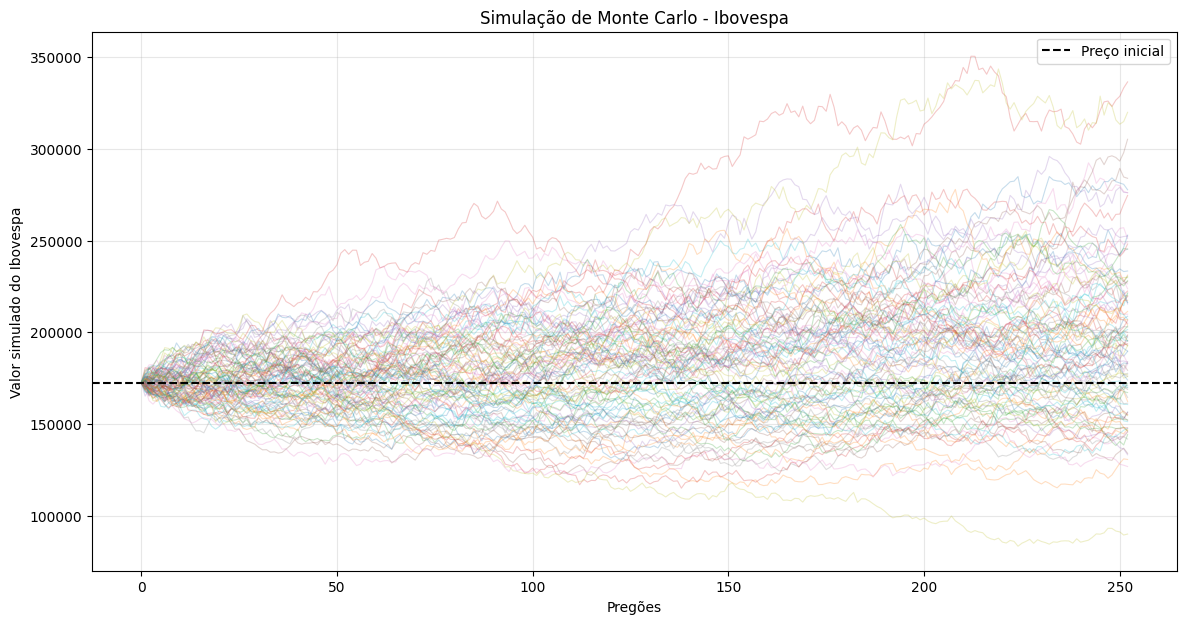

In [10]:
plt.figure(figsize=(14, 7))

tempo_mc = np.arange(N + 1)

for i in range(100):
    plt.plot(
        tempo_mc,
        trajetorias_mc[i],
        alpha=0.25,
        linewidth=0.8
    )

plt.axhline(
    S0,
    linestyle="--",
    color="black",
    label="Preço inicial"
)

plt.title("Simulação de Monte Carlo - Ibovespa")
plt.xlabel("Pregões")
plt.ylabel("Valor simulado do Ibovespa")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [11]:
# Extração dos preços finais
precos_finais = trajetorias_mc[:, -1]

# Estatísticas
print("Média:", np.mean(precos_finais))
print("Mediana:", np.median(precos_finais))
print("Desvio padrão:", np.std(precos_finais, ddof=1))

print("\nQuantis:")
print(np.quantile(precos_finais, [0.05, 0.25, 0.50, 0.75, 0.95]))

# Probabilidade empírica de valorização
prob_valorizacao = np.mean(precos_finais > S0)

print("\nProbabilidade simulada de valorização:",
      prob_valorizacao * 100, "%")

Média: 197222.73533824383
Mediana: 191796.44792042015
Desvio padrão: 46750.16578218557

Quantis:
[129571.49276083 164373.02209322 191796.44792042 224282.83379576
 282054.0834191 ]

Probabilidade simulada de valorização: 68.32000000000001 %


In [12]:
from scipy.stats import lognorm, norm

# Horizonte total: 252 pregões
T = 252

# Parâmetros da distribuição lognormal
desvio_log = volatilidade_diaria * np.sqrt(T)

media_log = (
    np.log(S0)
    + (mu_diario - 0.5 * volatilidade_diaria**2) * T
)

# Distribuição teórica
distribuicao_teorica = lognorm(
    s=desvio_log,
    scale=np.exp(media_log)
)

# Estatísticas teóricas
media_teorica = distribuicao_teorica.mean()
mediana_teorica = distribuicao_teorica.median()

prob_teorica = 1 - distribuicao_teorica.cdf(S0)

print(f"Média teórica: {media_teorica:.2f}")
print(f"Mediana teórica: {mediana_teorica:.2f}")
print(f"Probabilidade teórica de valorização: {prob_teorica * 100:.2f}%")

Média teórica: 197672.69
Mediana teórica: 192228.40
Probabilidade teórica de valorização: 67.70%


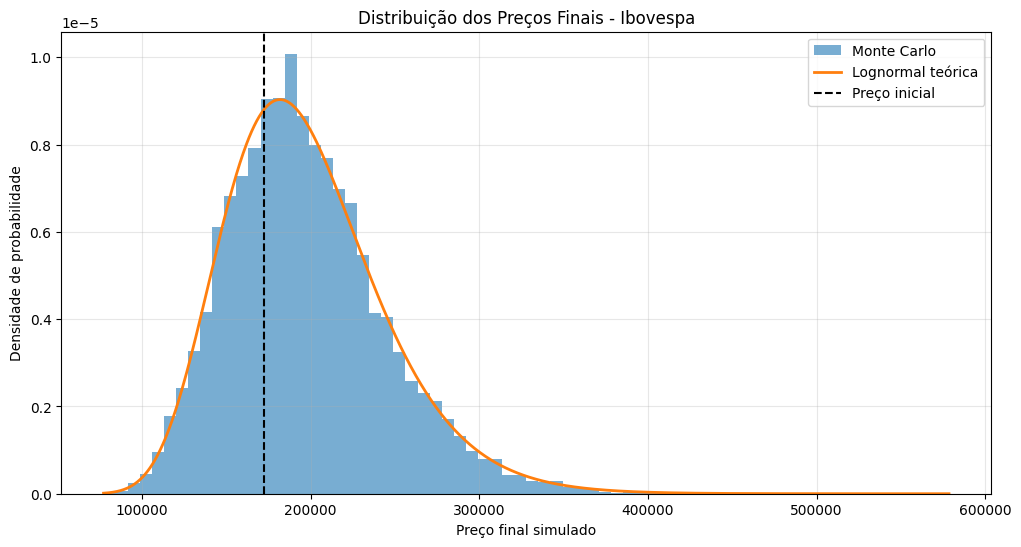

In [13]:
# Intervalo para a curva teórica
x_teorico = np.linspace(
    precos_finais.min(),
    precos_finais.max(),
    1000
)

# Densidade teórica
y_teorico = distribuicao_teorica.pdf(x_teorico)

plt.figure(figsize=(12, 6))

# Distribuição empírica
plt.hist(
    precos_finais,
    bins=70,
    density=True,
    alpha=0.6,
    label="Monte Carlo"
)

# Distribuição teórica
plt.plot(
    x_teorico,
    y_teorico,
    linewidth=2,
    label="Lognormal teórica"
)

plt.axvline(
    S0,
    linestyle="--",
    color="black",
    label="Preço inicial"
)

plt.title("Distribuição dos Preços Finais - Ibovespa")
plt.xlabel("Preço final simulado")
plt.ylabel("Densidade de probabilidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Comparação entre a distribuição simulada e a distribuição teórica

O histograma dos preços finais obtidos por Monte Carlo apresentou boa
concordância com a curva da distribuição lognormal teórica.

As pequenas diferenças observadas entre as duas distribuições são
atribuídas à variabilidade amostral decorrente do número finito de
simulações (10.000 trajetórias).

Esse resultado indica que a implementação numérica do Movimento
Browniano Geométrico está reproduzindo adequadamente o comportamento
teórico esperado pelo modelo.

Entretanto, essa concordância valida a implementação do modelo
matemático, não necessariamente sua capacidade de representar
integralmente o comportamento real do mercado financeiro.

## Limitações do Modelo

In [14]:
assimetria = retornos.skew()
curtose = retornos.kurt()

print(f"Assimetria: {assimetria:.6f}")
print(f"Curtose excedente: {curtose:.6f}")

Assimetria: -1.249240
Curtose excedente: 18.133451


### Análise de assimetria e curtose dos retornos históricos

A análise estatística dos retornos logarítmicos do Ibovespa apresentou:

- Assimetria: -1,249240.
- Curtose excedente: 18,133451.

A assimetria negativa indica uma distribuição com cauda esquerda
mais alongada, enquanto a elevada curtose excedente indica
caudas mais pesadas em comparação com a distribuição normal.

Esses resultados evidenciam diferenças importantes entre os
retornos históricos e a hipótese de normalidade utilizada no
Movimento Browniano Geométrico.

Assim, a concordância entre a simulação de Monte Carlo e a
distribuição lognormal teórica valida a implementação matemática,
mas não garante que o modelo represente adequadamente todos os
comportamentos observados no mercado financeiro.

## Comparação entre Monte Carlo gaussiano e Monte Carlo por bootstrap

In [15]:
print("Quantidade de retornos históricos:", len(retornos))
print("Menor retorno:", retornos.min())
print("Maior retorno:", retornos.max())
print("Média:", retornos.mean())
print("Desvio padrão:", retornos.std())

Quantidade de retornos históricos: 2945
Menor retorno: -0.159930265676043
Maior retorno: 0.1302228102427078
Média: 0.0004306765835466846
Desvio padrão: 0.014888030372760179


In [16]:
np.random.seed(42)

retornos_historicos = retornos.to_numpy()

retornos_bootstrap = np.random.choice(
    retornos_historicos,
    size=(M, N),
    replace=True
)

print("Dimensões:", retornos_bootstrap.shape)
print("Média:", retornos_bootstrap.mean())
print("Desvio padrão:", retornos_bootstrap.std())

Dimensões: (10000, 252)
Média: 0.00042561027083175615
Desvio padrão: 0.014878721130666033


In [17]:
trajetorias_bootstrap = np.zeros((M, N + 1))

trajetorias_bootstrap[:, 0] = S0

for t in range(N):
    trajetorias_bootstrap[:, t + 1] = (
        trajetorias_bootstrap[:, t]
        * np.exp(retornos_bootstrap[:, t])
    )

print("Dimensões:", trajetorias_bootstrap.shape)
print("Preço inicial:", trajetorias_bootstrap[0, 0])
print("Preço final da primeira trajetória:",
      trajetorias_bootstrap[0, -1])

Dimensões: (10000, 253)
Preço inicial: 172458.0
Preço final da primeira trajetória: 155651.84282222015


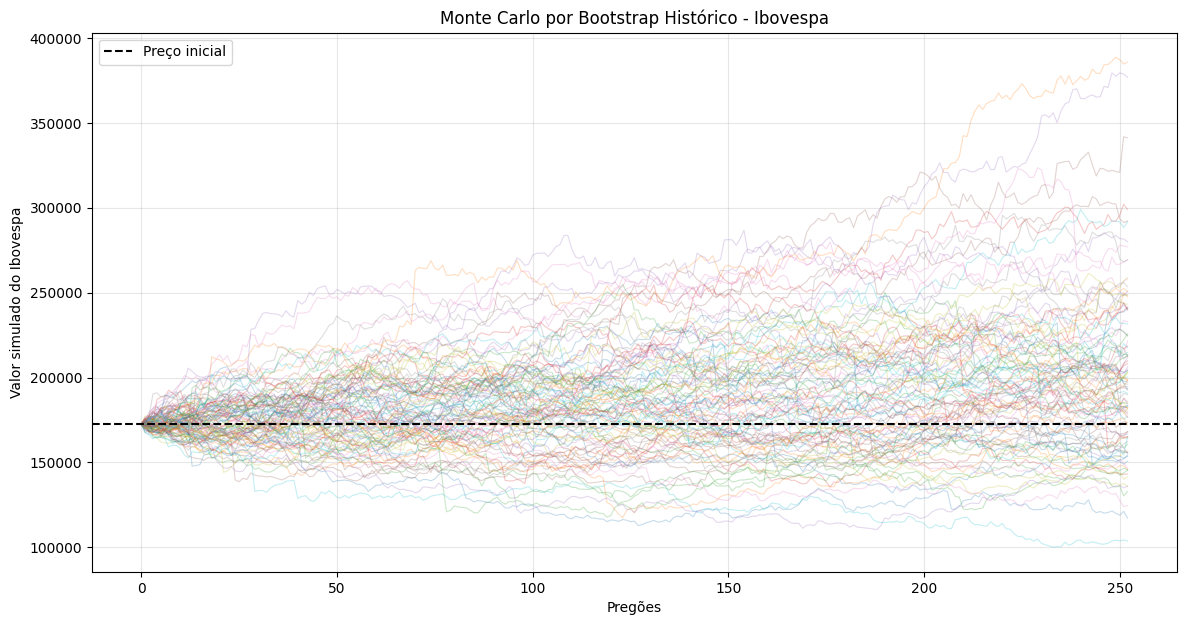

In [18]:
plt.figure(figsize=(14, 7))

tempo_mc = np.arange(N + 1)

for i in range(100):
    plt.plot(
        tempo_mc,
        trajetorias_bootstrap[i],
        alpha=0.25,
        linewidth=0.8
    )

plt.axhline(
    S0,
    linestyle="--",
    color="black",
    label="Preço inicial"
)

plt.title("Monte Carlo por Bootstrap Histórico - Ibovespa")
plt.xlabel("Pregões")
plt.ylabel("Valor simulado do Ibovespa")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
precos_finais_bootstrap = trajetorias_bootstrap[:, -1]

print("Média:", np.mean(precos_finais_bootstrap))
print("Mediana:", np.median(precos_finais_bootstrap))
print("Desvio padrão:", np.std(precos_finais_bootstrap, ddof=1))

print("\nQuantis:")
print(
    np.quantile(
        precos_finais_bootstrap,
        [0.05, 0.25, 0.50, 0.75, 0.95]
    )
)

prob_valorizacao_bootstrap = np.mean(
    precos_finais_bootstrap > S0
)

print(
    "\nProbabilidade simulada de valorização:",
    prob_valorizacao_bootstrap * 100,
    "%"
)

Média: 197368.29417734352
Mediana: 192495.87339128798
Desvio padrão: 46827.55130388363

Quantis:
[129640.3908558  164110.15937471 192495.87339129 225784.00451061
 281619.79179032]

Probabilidade simulada de valorização: 67.67999999999999 %


### Comparação entre Monte Carlo Gaussiano e Bootstrap Histórico

Foram implementadas duas abordagens de simulação:

1. GBM: utiliza incrementos normalmente distribuídos e volatilidade constante.
2. Bootstrap histórico: utiliza retornos logarítmicos sorteados com reposição
   diretamente da série histórica.

Os resultados apresentaram médias, medianas e desvios padrão próximos.
Entretanto, foram observadas diferenças nos quantis da distribuição
dos preços finais.

Essa comparação permite investigar o efeito da distribuição empírica
dos retornos sobre os cenários simulados, especialmente considerando
a assimetria negativa e a elevada curtose observadas nos dados históricos.

A proximidade das estatísticas centrais não implica equivalência
entre os modelos, sendo necessária uma investigação mais detalhada
das distribuições e dos eventos extremos.

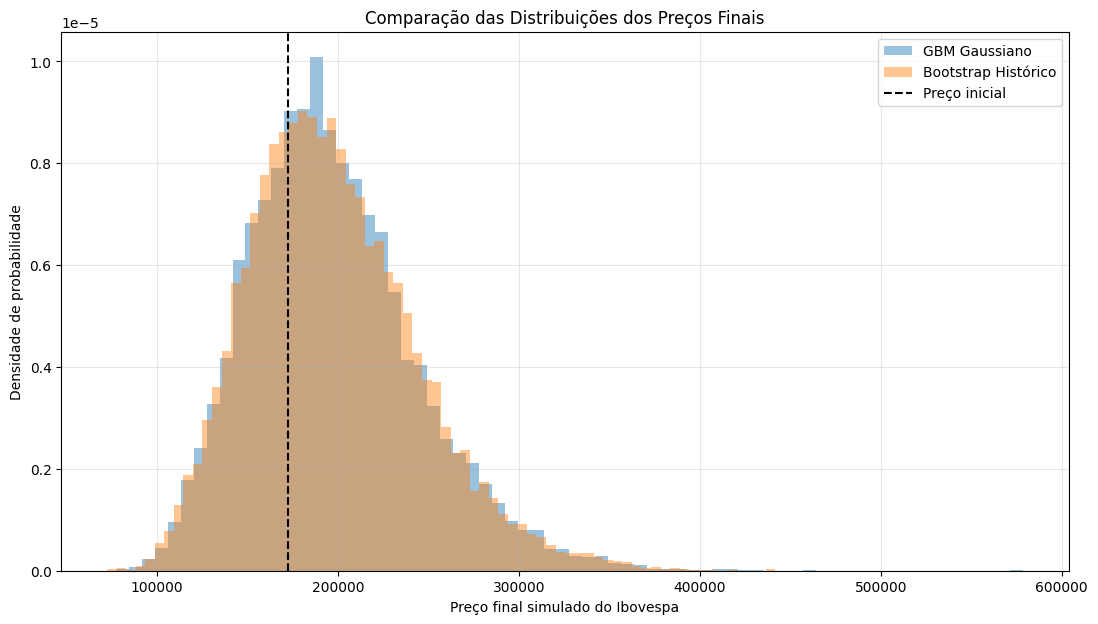

In [20]:
plt.figure(figsize=(13, 7))

plt.hist(
    precos_finais,
    bins=70,
    density=True,
    alpha=0.45,
    label="GBM Gaussiano"
)

plt.hist(
    precos_finais_bootstrap,
    bins=70,
    density=True,
    alpha=0.45,
    label="Bootstrap Histórico"
)

plt.axvline(
    S0,
    linestyle="--",
    color="black",
    label="Preço inicial"
)

plt.title("Comparação das Distribuições dos Preços Finais")
plt.xlabel("Preço final simulado do Ibovespa")
plt.ylabel("Densidade de probabilidade")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
from scipy.stats import skew, kurtosis

assimetria_gbm = skew(precos_finais)
curtose_gbm = kurtosis(precos_finais)

assimetria_bootstrap = skew(precos_finais_bootstrap)
curtose_bootstrap = kurtosis(precos_finais_bootstrap)

print("GBM Gaussiano")
print(f"Assimetria: {assimetria_gbm:.6f}")
print(f"Curtose excedente: {curtose_gbm:.6f}")

print("\nBootstrap Histórico")
print(f"Assimetria: {assimetria_bootstrap:.6f}")
print(f"Curtose excedente: {curtose_bootstrap:.6f}")

GBM Gaussiano
Assimetria: 0.736417
Curtose excedente: 1.246116

Bootstrap Histórico
Assimetria: 0.648745
Curtose excedente: 0.692188


### Assimetria e curtose das distribuições dos preços finais

A análise das distribuições simuladas apresentou:

| Estatística | GBM | Bootstrap |
|---|---:|---:|
| Assimetria | 0,736417 | 0,648745 |
| Curtose excedente | 1,246116 | 0,692188 |

Ambos os modelos apresentaram assimetria positiva e curtose
excedente positiva.

O GBM apresentou valores superiores nas duas medidas,
indicando maior assimetria e maior curtose na distribuição
dos preços finais simulados.

Esse resultado demonstra que as características estatísticas
dos retornos diários não são necessariamente reproduzidas
na mesma intensidade após a acumulação dos retornos ao longo
de 252 pregões.

In [22]:
var_95_gbm = S0 - np.quantile(precos_finais, 0.05)

var_95_bootstrap = (
    S0 - np.quantile(precos_finais_bootstrap, 0.05)
)

print(f"VaR 95% - GBM: {var_95_gbm:.2f}")
print(f"VaR 95% - Bootstrap: {var_95_bootstrap:.2f}")

print(
    f"\nVaR percentual - GBM: "
    f"{var_95_gbm / S0 * 100:.2f}%"
)

print(
    f"VaR percentual - Bootstrap: "
    f"{var_95_bootstrap / S0 * 100:.2f}%"
)

VaR 95% - GBM: 42886.51
VaR 95% - Bootstrap: 42817.61

VaR percentual - GBM: 24.87%
VaR percentual - Bootstrap: 24.83%


### Value at Risk (VaR) - Comparação entre os modelos

Foi calculado o VaR de 95% para o horizonte de 252 pregões,
utilizando o percentil de 5% das distribuições dos preços finais.

| Indicador | GBM | Bootstrap |
|---|---:|---:|
| VaR absoluto | 42.886,51 | 42.817,61 |
| VaR percentual | 24,87% | 24,83% |

Os resultados apresentaram uma diferença de apenas 0,04 ponto
percentual entre os modelos.

Essa proximidade indica que, para o percentil analisado,
as duas abordagens produziram estimativas semelhantes de perda.

Entretanto, o VaR não descreve a magnitude das perdas que
ultrapassam o percentil de 5%, sendo necessário complementar
a análise com o Conditional Value at Risk (CVaR).

In [23]:
limite_gbm = np.quantile(precos_finais, 0.05)

limite_bootstrap = np.quantile(
    precos_finais_bootstrap,
    0.05
)

perdas_gbm = S0 - precos_finais
perdas_bootstrap = S0 - precos_finais_bootstrap

cvar_95_gbm = perdas_gbm[
    precos_finais <= limite_gbm
].mean()

cvar_95_bootstrap = perdas_bootstrap[
    precos_finais_bootstrap <= limite_bootstrap
].mean()

print(f"CVaR 95% - GBM: {cvar_95_gbm:.2f}")
print(f"CVaR 95% - Bootstrap: {cvar_95_bootstrap:.2f}")

print(
    f"\nCVaR percentual - GBM: "
    f"{cvar_95_gbm / S0 * 100:.2f}%"
)

print(
    f"CVaR percentual - Bootstrap: "
    f"{cvar_95_bootstrap / S0 * 100:.2f}%"
)

CVaR 95% - GBM: 54573.86
CVaR 95% - Bootstrap: 55180.68

CVaR percentual - GBM: 31.64%
CVaR percentual - Bootstrap: 32.00%


### Conditional Value at Risk (CVaR) - Comparação entre os modelos

O CVaR de 95% foi calculado como a perda média observada
nos 5% piores cenários simulados.

| Indicador | GBM | Bootstrap |
|---|---:|---:|
| VaR 95% | 24,87% | 24,83% |
| CVaR 95% | 31,64% | 32,00% |

Embora os modelos apresentem estimativas semelhantes de VaR,
o bootstrap apresentou CVaR ligeiramente superior.

Esse resultado evidencia a importância de analisar não apenas
o limiar de perda, mas também a magnitude média das perdas
nos cenários mais desfavoráveis.

A comparação demonstra como diferentes hipóteses sobre a
distribuição dos retornos podem influenciar as medidas de
risco de cauda.

In [24]:
np.random.seed(123)

M_convergencia = 50000
N_convergencia = 252

Z_convergencia = np.random.normal(
    0,
    1,
    size=(M_convergencia, N_convergencia)
)

print("Dimensões:", Z_convergencia.shape)
print("Média:", Z_convergencia.mean())
print("Desvio padrão:", Z_convergencia.std())

Dimensões: (50000, 252)
Média: 0.00024845131944453404
Desvio padrão: 1.0002068674583764


In [25]:
trajetorias_gbm_50k = np.zeros(
    (M_convergencia, N_convergencia + 1)
)

trajetorias_gbm_50k[:, 0] = S0

for t in range(N_convergencia):
    trajetorias_gbm_50k[:, t + 1] = (
        trajetorias_gbm_50k[:, t]
        * np.exp(
            (mu_diario - 0.5 * volatilidade_diaria**2)
            + volatilidade_diaria * Z_convergencia[:, t]
        )
    )

print("Dimensões:", trajetorias_gbm_50k.shape)

precos_finais_gbm_50k = trajetorias_gbm_50k[:, -1]

print(
    "Média dos preços finais:",
    precos_finais_gbm_50k.mean()
)

print(
    "Mediana dos preços finais:",
    np.median(precos_finais_gbm_50k)
)

Dimensões: (50000, 253)
Média dos preços finais: 197875.7995523629
Mediana dos preços finais: 192210.68843156475


In [26]:
limite_gbm_50k = np.quantile(
    precos_finais_gbm_50k,
    0.05
)

perdas_gbm_50k = S0 - precos_finais_gbm_50k

var_gbm_50k = S0 - limite_gbm_50k

cvar_gbm_50k = perdas_gbm_50k[
    precos_finais_gbm_50k <= limite_gbm_50k
].mean()

print(f"VaR 95%: {var_gbm_50k:.2f}")
print(f"VaR percentual: {var_gbm_50k / S0 * 100:.2f}%")

print(f"\nCVaR 95%: {cvar_gbm_50k:.2f}")
print(f"CVaR percentual: {cvar_gbm_50k / S0 * 100:.2f}%")

VaR 95%: 41905.00
VaR percentual: 24.30%

CVaR 95%: 54104.36
CVaR percentual: 31.37%


### Convergência estatística do Monte Carlo - GBM

Foram realizadas simulações com 10.000 e 50.000 trajetórias,
mantendo os mesmos parâmetros e o horizonte de 252 pregões.

| Indicador | 10.000 | 50.000 |
|---|---:|---:|
| VaR 95% | 24,87% | 24,30% |
| CVaR 95% | 31,64% | 31,37% |

O aumento da quantidade de trajetórias produziu alterações
nas estimativas de risco, mas os resultados permaneceram
relativamente próximos.

Essa análise demonstra a influência da variabilidade amostral
sobre os estimadores de risco de cauda.

A convergência deve ser investigada com diferentes tamanhos
amostrais e sementes aleatórias, não apenas por uma comparação
isolada entre duas simulações.

In [27]:
np.random.seed(123)

retornos_bootstrap_50k = np.random.choice(
    retornos_historicos,
    size=(M_convergencia, N_convergencia),
    replace=True
)

print("Dimensões:", retornos_bootstrap_50k.shape)
print("Média:", retornos_bootstrap_50k.mean())
print("Desvio padrão:", retornos_bootstrap_50k.std())

Dimensões: (50000, 252)
Média: 0.00043512186738757427
Desvio padrão: 0.014875797495061812


In [28]:
precos_finais_bootstrap_50k = (
    S0 * np.exp(retornos_bootstrap_50k.sum(axis=1))
)

print("Quantidade de preços:", len(precos_finais_bootstrap_50k))
print("Média:", precos_finais_bootstrap_50k.mean())
print("Mediana:", np.median(precos_finais_bootstrap_50k))
print("Desvio padrão:", precos_finais_bootstrap_50k.std(ddof=1))

Quantidade de preços: 50000
Média: 197911.38663552247
Mediana: 192871.3251854521
Desvio padrão: 47203.62309851469


In [29]:
limite_bootstrap_50k = np.quantile(
    precos_finais_bootstrap_50k,
    0.05
)

perdas_bootstrap_50k = (
    S0 - precos_finais_bootstrap_50k
)

var_bootstrap_50k = S0 - limite_bootstrap_50k

cvar_bootstrap_50k = perdas_bootstrap_50k[
    precos_finais_bootstrap_50k <= limite_bootstrap_50k
].mean()

print(f"VaR 95%: {var_bootstrap_50k:.2f}")
print(f"VaR percentual: {var_bootstrap_50k / S0 * 100:.2f}%")

print(f"\nCVaR 95%: {cvar_bootstrap_50k:.2f}")
print(f"CVaR percentual: {cvar_bootstrap_50k / S0 * 100:.2f}%")

VaR 95%: 42827.38
VaR percentual: 24.83%

CVaR 95%: 55503.99
CVaR percentual: 32.18%


### Comparação de convergência: GBM versus Bootstrap

Foram realizadas simulações com 10.000 e 50.000 trajetórias para os modelos GBM e Bootstrap Histórico, considerando um horizonte de 252 pregões.

| Modelo | Simulações | VaR 95% | CVaR 95% |
|---|---:|---:|---:|
| GBM | 10.000 | 24,87% | 31,64% |
| GBM | 50.000 | 24,30% | 31,37% |
| Bootstrap | 10.000 | 24,83% | 32,00% |
| Bootstrap | 50.000 | 24,83% | 32,18% |

**Análise:**

O aumento do número de trajetórias permitiu observar a estabilidade das estimativas de risco. O modelo GBM apresentou pequenas alterações no VaR e no CVaR, enquanto o Bootstrap manteve o VaR praticamente constante.

Na simulação de 50.000 trajetórias, o Bootstrap apresentou CVaR de 32,18%, superior aos 31,37% do GBM.

Os resultados evidenciam que diferentes hipóteses sobre a distribuição dos retornos podem produzir estimativas distintas de risco extremo.

Aumentar o número de simulações reduz a variabilidade numérica, mas não elimina as limitações das hipóteses de cada modelo.

In [30]:
tamanhos_amostrais = [1000, 5000, 10000, 20000, 50000]

print("Tamanhos amostrais:", tamanhos_amostrais)

Tamanhos amostrais: [1000, 5000, 10000, 20000, 50000]


In [31]:
np.random.seed(2026)

M_max = 50000
N = 252

Z_convergencia = np.random.normal(
    0, 1,
    size=(M_max, N)
)

precos_finais_convergencia = S0 * np.exp(
    (mu_diario - 0.5 * volatilidade_diaria**2) * N
    + volatilidade_diaria * Z_convergencia.sum(axis=1)
)

print("Quantidade de simulações:", len(precos_finais_convergencia))
print("Média:", precos_finais_convergencia.mean())
print("Mediana:", np.median(precos_finais_convergencia))

Quantidade de simulações: 50000
Média: 197665.0906357807
Mediana: 192358.42091154872


In [32]:
resultados_convergencia = []

for M_atual in tamanhos_amostrais:

    precos = precos_finais_convergencia[:M_atual]

    limite = np.quantile(precos, 0.05)

    perdas = S0 - precos

    var = S0 - limite

    cvar = perdas[precos <= limite].mean()

    resultados_convergencia.append({
        "Simulacoes": M_atual,
        "VaR_95": var,
        "VaR_percentual": var / S0 * 100,
        "CVaR_95": cvar,
        "CVaR_percentual": cvar / S0 * 100
    })

df_convergencia = pd.DataFrame(resultados_convergencia)

df_convergencia.round(2)

,Simulacoes,VaR_95,VaR_percentual,CVaR_95,CVaR_percentual
0,1000,38855.03,22.53,52965.00,30.71
1,5000,42079.79,24.40,53441.21,30.99
2,10000,42581.52,24.69,54340.18,31.51
3,20000,42409.52,24.59,54408.98,31.55
4,50000,41963.96,24.33,54049.51,31.34


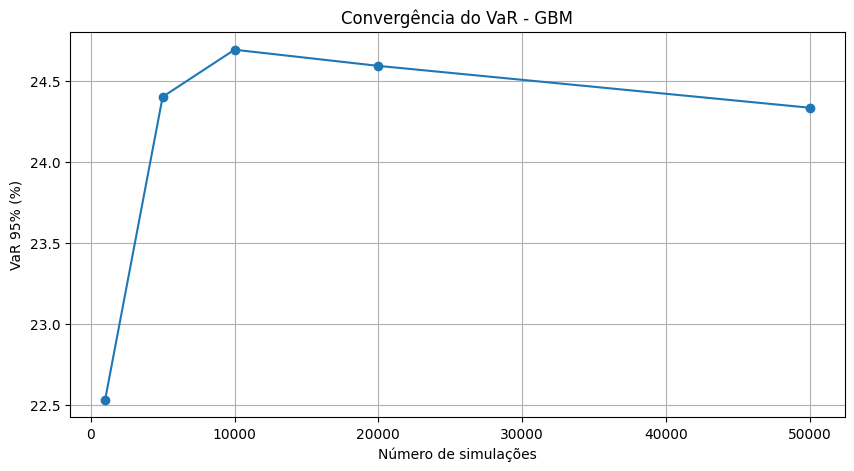

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_convergencia["Simulacoes"],
    df_convergencia["VaR_percentual"],
    marker="o"
)

plt.xlabel("Número de simulações")
plt.ylabel("VaR 95% (%)")
plt.title("Convergência do VaR - GBM")
plt.grid(True)
plt.show()

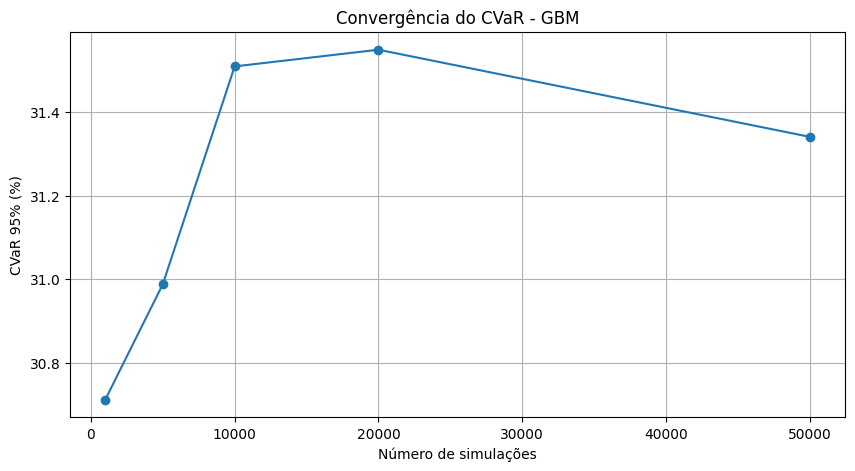

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_convergencia["Simulacoes"],
    df_convergencia["CVaR_percentual"],
    marker="o"
)

plt.xlabel("Número de simulações")
plt.ylabel("CVaR 95% (%)")
plt.title("Convergência do CVaR - GBM")
plt.grid(True)
plt.show()

### Análise gráfica da convergência do GBM

Os gráficos de convergência do VaR e do CVaR apresentam um comportamento semelhante: inicialmente, as estimativas aumentam e, posteriormente, passam a oscilar em uma faixa relativamente estável.

Esse comportamento está relacionado à variabilidade amostral. Com poucas trajetórias, as estimativas dos quantis e das perdas médias na cauda são mais sensíveis à composição da amostra.

Com o aumento do número de simulações, as estimativas apresentam maior estabilidade numérica.

Entretanto, a convergência numérica não elimina as limitações das hipóteses matemáticas do modelo GBM.

In [35]:
precos_finais_bootstrap_convergencia = (
    S0 * np.exp(
        retornos_bootstrap_50k.cumsum(axis=1)[:, -1]
    )
)

print("Quantidade:", len(precos_finais_bootstrap_convergencia))
print("Média:", precos_finais_bootstrap_convergencia.mean())
print("Mediana:", np.median(precos_finais_bootstrap_convergencia))

Quantidade: 50000
Média: 197911.38663552247
Mediana: 192871.32518545212


In [36]:
resultados_bootstrap_convergencia = []

for M_atual in tamanhos_amostrais:

    precos = precos_finais_bootstrap_convergencia[:M_atual]

    limite = np.quantile(precos, 0.05)

    perdas = S0 - precos

    var = S0 - limite

    cvar = perdas[precos <= limite].mean()

    resultados_bootstrap_convergencia.append({
        "Simulacoes": M_atual,
        "VaR_95": var,
        "VaR_percentual": var / S0 * 100,
        "CVaR_95": cvar,
        "CVaR_percentual": cvar / S0 * 100
    })

df_bootstrap_convergencia = pd.DataFrame(
    resultados_bootstrap_convergencia
)

df_bootstrap_convergencia.round(2)

,Simulacoes,VaR_95,VaR_percentual,CVaR_95,CVaR_percentual
0,1000,44290.27,25.68,57810.96,33.52
1,5000,44241.75,25.65,55296.67,32.06
2,10000,43628.45,25.30,55623.93,32.25
3,20000,43188.95,25.04,55559.75,32.22
4,50000,42827.38,24.83,55503.99,32.18


### Comparação da convergência: GBM e Bootstrap Histórico

A análise de convergência foi realizada com 1.000, 5.000, 10.000, 20.000 e 50.000 simulações.

Os dois modelos apresentaram oscilações mais expressivas nas amostras menores, seguidas de maior estabilidade numérica.

O GBM apresentou VaR de 24,30% e CVaR de 31,37% na simulação anterior de 50.000 trajetórias. No experimento de convergência, utilizando outra semente aleatória, os resultados foram 24,33% e 31,34%, respectivamente.

O Bootstrap Histórico apresentou VaR de 24,83% e CVaR de 32,18%.

A diferença entre os modelos sugere que a distribuição empírica dos retornos históricos pode produzir estimativas de risco de cauda diferentes das obtidas sob a hipótese de retornos gaussianos do GBM.

Conclui-se que o aumento do número de simulações contribui para a estabilidade numérica dos estimadores, mas não elimina o risco de especificação do modelo.

## Investigando a volatididade histórica 

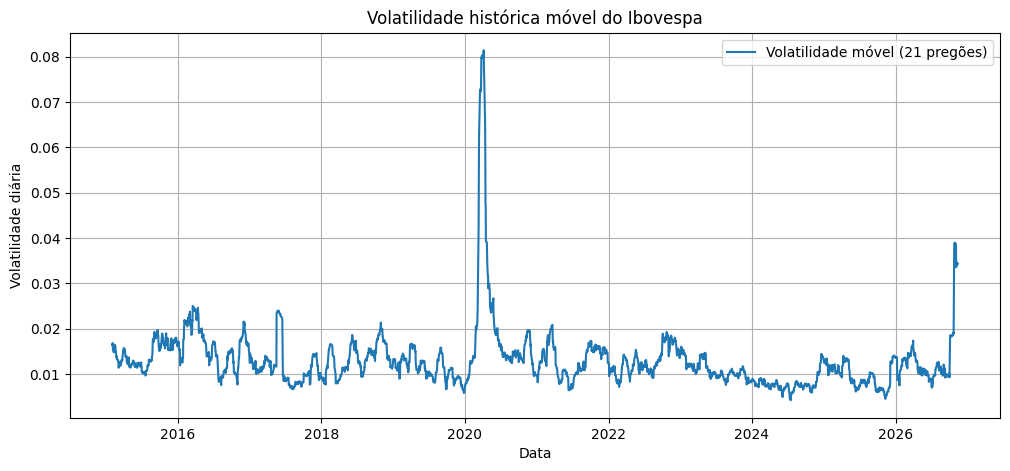

In [37]:
volatilidade_movel = retornos.rolling(window=21).std()

plt.figure(figsize=(12, 5))

plt.plot(
    volatilidade_movel.index,
    volatilidade_movel,
    label="Volatilidade móvel (21 pregões)"
)

plt.xlabel("Data")
plt.ylabel("Volatilidade diária")
plt.title("Volatilidade histórica móvel do Ibovespa")
plt.legend()
plt.grid(True)
plt.show()

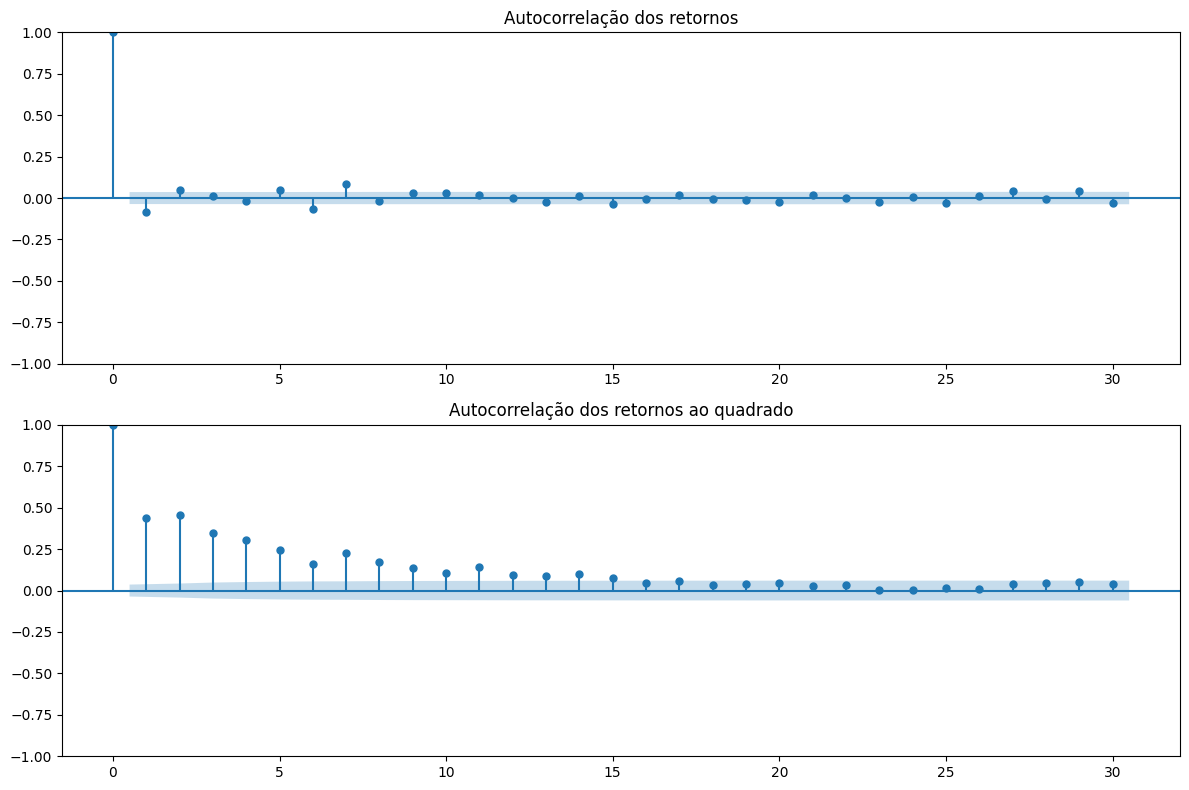

In [38]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    retornos,
    lags=30,
    ax=ax[0],
    title="Autocorrelação dos retornos"
)

plot_acf(
    retornos**2,
    lags=30,
    ax=ax[1],
    title="Autocorrelação dos retornos ao quadrado"
)

plt.tight_layout()
plt.show()

In [39]:
from statsmodels.tsa.stattools import acf

acf_retornos = acf(retornos, nlags=10)
acf_quadrados = acf(retornos**2, nlags=10)

comparacao_acf = pd.DataFrame({
    "Lag": range(11),
    "Retornos": acf_retornos,
    "Retornos_Quadrados": acf_quadrados
})

comparacao_acf.round(4)

,Lag,Retornos,Retornos_Quadrados
0,0,1.0000,1.0000
1,1,-0.0852,0.4360
2,2,0.0494,0.4547
3,3,0.0130,0.3451
4,4,-0.0171,0.3060
5,5,0.0515,0.2431
6,6,-0.0662,0.1607
7,7,0.0859,0.2258
8,8,-0.0198,0.1736
9,9,0.0290,0.1381


In [40]:
from statsmodels.stats.diagnostic import acorr_ljungbox

teste_retornos = acorr_ljungbox(
    retornos,
    lags=[10, 20],
    return_df=True
)

teste_quadrados = acorr_ljungbox(
    retornos**2,
    lags=[10, 20],
    return_df=True
)

print("Teste nos retornos:")
display(teste_retornos)

print("Teste nos retornos ao quadrado:")
display(teste_quadrados)

Teste nos retornos:


,lb_stat,lb_pvalue
10,78.630257,9.310483e-13
20,88.724950,1.237533e-10


Teste nos retornos ao quadrado:


,lb_stat,lb_pvalue
10,2376.378756,0.0
20,2564.988277,0.0


### Teste de Ljung-Box: dependência temporal

O teste de Ljung-Box foi aplicado aos retornos logarítmicos e aos retornos logarítmicos ao quadrado, considerando 10 e 20 defasagens.

Os resultados apresentaram valores-p inferiores a 0,05 em todas as análises, levando à rejeição da hipótese nula de ausência de autocorrelação conjunta.

A dependência observada nos retornos ao quadrado é particularmente expressiva, constituindo evidência de agrupamento de volatilidade (*volatility clustering*).

Esses resultados justificam investigar modelos de volatilidade condicional, como o GARCH(1,1).

In [44]:
retornos_pct = retornos * 100

print("Média:", retornos_pct.mean())
print("Desvio padrão:", retornos_pct.std())
print("Quantidade:", len(retornos_pct))

Média: 0.043067658354668456
Desvio padrão: 1.488803037276018
Quantidade: 2945


In [45]:
import importlib.util

print("Biblioteca arch instalada:",
      importlib.util.find_spec("arch") is not None)

Biblioteca arch instalada: False


In [46]:
%pip install arch

  Using cached arch-9.0.0-cp311-cp311-win_amd64.whl.metadata (12 kB)
Using cached arch-9.0.0-cp311-cp311-win_amd64.whl (1.4 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Mateus.RH\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [48]:
import arch

print("Versão:", arch.__version__)

Versão: 9.0.0


In [49]:
from arch import arch_model

modelo_garch = arch_model(
    retornos_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

resultado_garch = modelo_garch.fit(disp="off")

print(resultado_garch.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:            Retorno_Log   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4954.94
Distribution:                  Normal   AIC:                           9917.87
Method:            Maximum Likelihood   BIC:                           9941.82
                                        No. Observations:                 2945
Date:                Tue, Nov 24 2026   Df Residuals:                     2944
Time:                        09:47:34   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0539  2.357e-02      2.287  2.218e-02 [7.712e-0

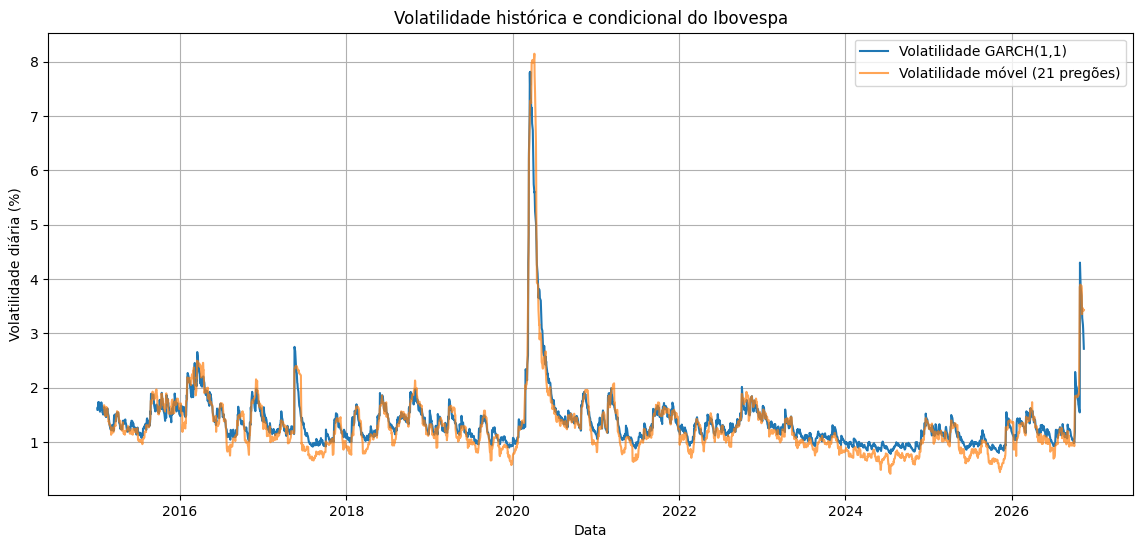

In [50]:
volatilidade_garch = resultado_garch.conditional_volatility

volatilidade_movel_pct = (
    retornos.rolling(window=21).std() * 100
)

plt.figure(figsize=(14, 6))

plt.plot(
    retornos.index,
    volatilidade_garch,
    label="Volatilidade GARCH(1,1)"
)

plt.plot(
    retornos.index,
    volatilidade_movel_pct,
    label="Volatilidade móvel (21 pregões)",
    alpha=0.7
)

plt.title("Volatilidade histórica e condicional do Ibovespa")
plt.xlabel("Data")
plt.ylabel("Volatilidade diária (%)")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
from statsmodels.stats.diagnostic import acorr_ljungbox

residuos_padronizados = resultado_garch.std_resid.dropna()

teste_residuos = acorr_ljungbox(
    residuos_padronizados,
    lags=[10, 20],
    return_df=True
)

teste_residuos_quadrados = acorr_ljungbox(
    residuos_padronizados**2,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box dos resíduos:")
display(teste_residuos)

print("Ljung-Box dos resíduos ao quadrado:")
display(teste_residuos_quadrados)

Ljung-Box dos resíduos:


,lb_stat,lb_pvalue
10,4.616467,0.915284
20,7.500733,0.994689


Ljung-Box dos resíduos ao quadrado:


,lb_stat,lb_pvalue
10,1.540552,9.988034e-01
20,77.877180,8.973926e-09


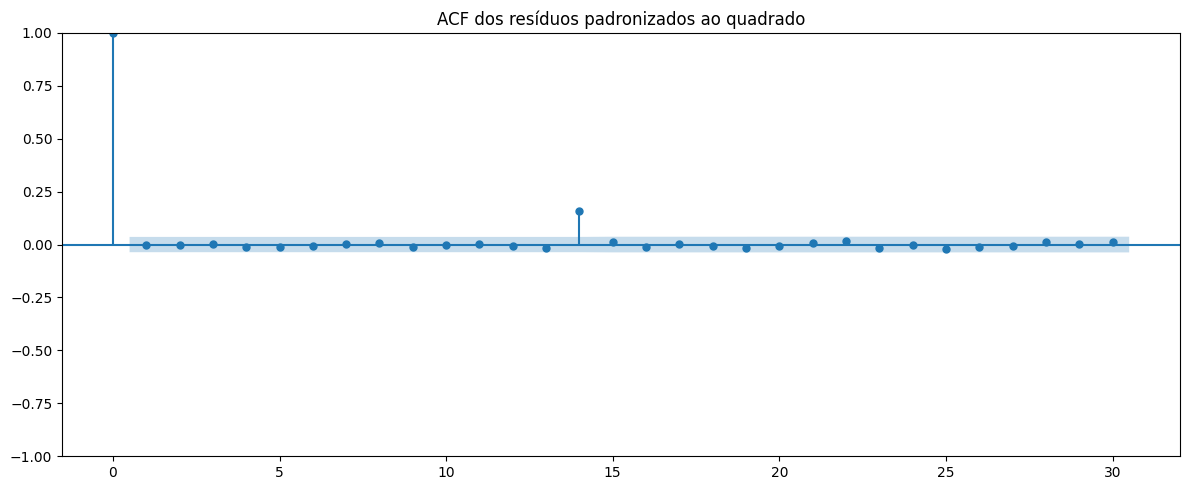

In [52]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    residuos_padronizados**2,
    lags=30,
    ax=ax,
    title="ACF dos resíduos padronizados ao quadrado"
)

plt.tight_layout()
plt.show()

In [53]:
teste_lags = acorr_ljungbox(
    residuos_padronizados**2,
    lags=[10, 15, 20, 25, 30],
    return_df=True
)

display(teste_lags)

,lb_stat,lb_pvalue
10,1.540552,9.988034e-01
15,76.120957,3.549699e-10
20,77.877180,8.973926e-09
25,81.354114,6.989269e-08
30,82.889312,7.528574e-07


In [54]:
modelo_garch_t = arch_model(
    retornos_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

resultado_garch_t = modelo_garch_t.fit(disp="off")

print(resultado_garch_t.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                  Retorno_Log   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -4850.99
Distribution:      Standardized Student's t   AIC:                           9711.99
Method:                  Maximum Likelihood   BIC:                           9741.92
                                              No. Observations:                 2945
Date:                      Tue, Nov 24 2026   Df Residuals:                     2944
Time:                              09:49:47   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [55]:
residuos_t = resultado_garch_t.std_resid.dropna()

teste_residuos_t = acorr_ljungbox(
    residuos_t,
    lags=[10, 20, 30],
    return_df=True
)

teste_quadrados_t = acorr_ljungbox(
    residuos_t**2,
    lags=[10, 15, 20, 25, 30],
    return_df=True
)

print("Ljung-Box dos resíduos — GARCH t:")
display(teste_residuos_t)

print("Ljung-Box dos resíduos ao quadrado — GARCH t:")
display(teste_quadrados_t)

Ljung-Box dos resíduos — GARCH t:


,lb_stat,lb_pvalue
10,4.938254,0.895264
20,7.946490,0.992216
30,20.552733,0.901351


Ljung-Box dos resíduos ao quadrado — GARCH t:


,lb_stat,lb_pvalue
10,1.791093,9.977050e-01
15,79.088154,1.024942e-10
20,80.524569,3.197563e-09
25,83.734969,2.931232e-08
30,85.292233,3.334584e-07


In [56]:
modelo_gjr = arch_model(
    retornos_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

resultado_gjr = modelo_gjr.fit(disp="off")

print(resultado_gjr.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                  Retorno_Log   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -4846.41
Distribution:      Standardized Student's t   AIC:                           9704.81
Method:                  Maximum Likelihood   BIC:                           9740.74
                                              No. Observations:                 2945
Date:                      Tue, Nov 24 2026   Df Residuals:                     2944
Time:                              09:50:46   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [57]:
residuos_gjr = resultado_gjr.std_resid.dropna()

teste_gjr = acorr_ljungbox(
    residuos_gjr,
    lags=[10, 20, 30],
    return_df=True
)

teste_gjr_quadrados = acorr_ljungbox(
    residuos_gjr**2,
    lags=[10, 15, 20, 25, 30],
    return_df=True
)

print("Ljung-Box dos resíduos — GJR-GARCH:")
display(teste_gjr)

print("Ljung-Box dos resíduos ao quadrado — GJR-GARCH:")
display(teste_gjr_quadrados)

Ljung-Box dos resíduos — GJR-GARCH:


,lb_stat,lb_pvalue
10,4.254493,0.935137
20,7.812578,0.993037
30,20.885995,0.891419


Ljung-Box dos resíduos ao quadrado — GJR-GARCH:


,lb_stat,lb_pvalue
10,0.840988,9.999227e-01
15,112.396146,5.582545e-17
20,113.433111,4.627483e-15
25,115.389647,1.427682e-13
30,116.407355,4.054343e-12


In [58]:
modelo_egarch = arch_model(
    retornos_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t"
)

resultado_egarch = modelo_egarch.fit(disp="off")

print(resultado_egarch.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                  Retorno_Log   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -4840.12
Distribution:      Standardized Student's t   AIC:                           9692.25
Method:                  Maximum Likelihood   BIC:                           9728.17
                                              No. Observations:                 2945
Date:                      Tue, Nov 24 2026   Df Residuals:                     2944
Time:                              09:51:42   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [59]:
residuos_egarch = resultado_egarch.std_resid.dropna()

teste_egarch = acorr_ljungbox(
    residuos_egarch,
    lags=[10, 20, 30],
    return_df=True
)

teste_egarch_quadrados = acorr_ljungbox(
    residuos_egarch**2,
    lags=[10, 15, 20, 25, 30],
    return_df=True
)

print("Ljung-Box dos resíduos — EGARCH:")
display(teste_egarch)

print("Ljung-Box dos resíduos ao quadrado — EGARCH:")
display(teste_egarch_quadrados)

Ljung-Box dos resíduos — EGARCH:


,lb_stat,lb_pvalue
10,5.992742,0.815873
20,9.975918,0.968607
30,22.437433,0.837663


Ljung-Box dos resíduos ao quadrado — EGARCH:


,lb_stat,lb_pvalue
10,0.818307,9.999319e-01
15,120.203105,1.728291e-18
20,121.096773,1.785712e-16
25,122.787501,7.118764e-15
30,123.924617,2.229521e-13


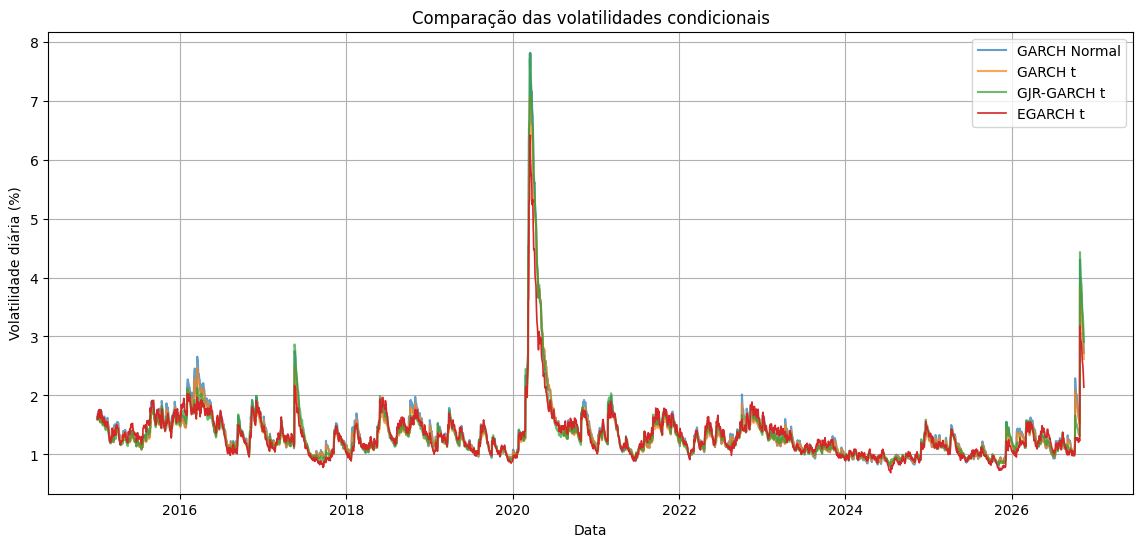

In [60]:
plt.figure(figsize=(14, 6))

plt.plot(
    retornos.index,
    resultado_garch.conditional_volatility,
    label="GARCH Normal",
    alpha=0.7
)

plt.plot(
    retornos.index,
    resultado_garch_t.conditional_volatility,
    label="GARCH t",
    alpha=0.7
)

plt.plot(
    retornos.index,
    resultado_gjr.conditional_volatility,
    label="GJR-GARCH t",
    alpha=0.7
)

plt.plot(
    retornos.index,
    resultado_egarch.conditional_volatility,
    label="EGARCH t",
    linewidth=1.2
)

plt.title("Comparação das volatilidades condicionais")
plt.xlabel("Data")
plt.ylabel("Volatilidade diária (%)")
plt.legend()
plt.grid(True)
plt.show()

In [61]:
vol = resultado_egarch.conditional_volatility

q25 = vol.quantile(0.25)
q75 = vol.quantile(0.75)

regimes = pd.Series(
    np.select(
        [vol <= q25, vol >= q75],
        ["Baixa", "Alta"],
        default="Intermediária"
    ),
    index=vol.index,
    name="Regime"
)

print("Limite de baixa volatilidade:", q25)
print("Limite de alta volatilidade:", q75)

print("\nDistribuição dos regimes:")
display(regimes.value_counts())

Limite de baixa volatilidade: 1.0671739268463736
Limite de alta volatilidade: 1.4836813834813376

Distribuição dos regimes:


Regime
Intermediária    1471
Alta              737
Baixa             737
Name: count, dtype: int64

 Modelagem da Volatilidade

Nesta etapa, foram investigadas as propriedades temporais da volatilidade dos retornos logarítmicos do Ibovespa por meio de modelos GARCH.

Inicialmente, a análise da autocorrelação dos retornos ao quadrado e o teste Ljung-Box forneceram evidências de agrupamentos de volatilidade (*volatility clustering*).

Foram estimados quatro modelos: GARCH(1,1) com distribuição normal, GARCH(1,1) com distribuição t de Student, GJR-GARCH e EGARCH.

A distribuição t apresentou melhor ajuste que a normal, enquanto os modelos assimétricos permitiram investigar diferenças na resposta da volatilidade a choques positivos e negativos.

Entre as especificações avaliadas, o EGARCH com distribuição t apresentou os menores valores de AIC e BIC. Entretanto, os testes dos resíduos padronizados ao quadrado indicaram que ainda existe dependência temporal não explicada.

Os resultados demonstram a importância de considerar volatilidade variável no tempo, distribuições com caudas pesadas e possíveis efeitos assimétricos na análise de séries financeiras.

## Conclusão — Método de Monte Carlo aplicado aos mercados financeiros

Nesta etapa, foi desenvolvido um estudo de simulação estocástica aplicado ao Ibovespa, utilizando o método de Monte Carlo para investigar diferentes cenários possíveis para a evolução dos preços ao longo de 252 pregões.

Inicialmente, foram estimados os parâmetros de retorno médio e volatilidade a partir dos dados históricos, permitindo construir trajetórias simuladas por meio do Movimento Browniano Geométrico (GBM). Os resultados foram comparados com a distribuição lognormal teórica, apresentando proximidade entre as estimativas simuladas e os valores analíticos esperados.

Posteriormente, foi implementada uma abordagem de *bootstrap* histórico, na qual os retornos observados foram reamostrados com reposição. Essa abordagem permitiu comparar um modelo baseado em retornos gaussianos com outro que preserva a distribuição empírica dos retornos históricos.

Também foram calculadas medidas de risco, como Value at Risk (VaR) e Conditional Value at Risk (CVaR), em nível de confiança de 95%. Os experimentos evidenciaram diferenças entre os modelos na representação das perdas extremas, especialmente na estimativa da perda média na cauda da distribuição.

A análise de convergência, utilizando diferentes quantidades de simulações, permitiu observar a estabilização gradual das estimativas de risco à medida que o número de trajetórias aumentava.

Por fim, foram investigadas as propriedades temporais da volatilidade, identificando evidências de agrupamento de volatilidade (*volatility clustering*), assimetria e persistência nos retornos históricos. Para isso, foram estudados modelos GARCH, GJR-GARCH e EGARCH, considerando distribuições normal e t de Student. O EGARCH com distribuição t apresentou o menor AIC e BIC entre as especificações avaliadas, embora os diagnósticos tenham indicado dependência residual ainda não explicada.

De maneira geral, os experimentos demonstraram como métodos de simulação estocástica, processos probabilísticos e modelos de volatilidade condicional podem ser utilizados conjuntamente para investigar a incerteza e a dinâmica dos mercados financeiros.

**Conexão com a Física Estatística:** o método de Monte Carlo estabelece uma base computacional para estudar sistemas complexos e fenômenos coletivos. Essa perspectiva será aprofundada na próxima etapa, com a implementação do modelo de Ising, permitindo investigar como interações locais entre agentes podem produzir comportamentos coletivos semelhantes a fenômenos observados nos mercados financeiros.